In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Semua library berhasil diimpor")

Semua library berhasil diimpor


In [4]:
df = pd.read_csv("online_gaming_behavior_dataset.csv")

print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

display(df.head())

Jumlah baris: 40034
Jumlah kolom: 13


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


In [5]:
assert df.shape[0] >= 1000, "Jumlah baris belum mencapai 1.000."
assert df.shape[1] >= 3, "Jumlah kolom belum mencapai 3."

print("Dataset memenuhi persyaratan minimal tugas.")

Dataset memenuhi persyaratan minimal tugas.


In [6]:
print("Informasi dataset:")
df.info()

print("\nJumlah nilai kosong:")
print(df.isnull().sum())

print("\nJumlah baris duplikat:")
print(df.duplicated().sum())

print("\nStatistik data numerik:")
display(df.describe())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int64  
 1   Age                        40034 non-null  int64  
 2   Gender                     40034 non-null  str    
 3   Location                   40034 non-null  str    
 4   GameGenre                  40034 non-null  str    
 5   PlayTimeHours              40034 non-null  float64
 6   InGamePurchases            40034 non-null  int64  
 7   GameDifficulty             40034 non-null  str    
 8   SessionsPerWeek            40034 non-null  int64  
 9   AvgSessionDurationMinutes  40034 non-null  int64  
 10  PlayerLevel                40034 non-null  int64  
 11  AchievementsUnlocked       40034 non-null  int64  
 12  EngagementLevel            40034 non-null  str    
dtypes: float64(1), int64(7), str(5)
memory

,PlayerID,Age,PlayTimeHours,InGamePurchases,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
count,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000,40034.000000
mean,29016.500000,31.992531,12.024365,0.200854,9.471774,94.792252,49.655568,24.526477
std,11556.964675,10.043227,6.914638,0.400644,5.763667,49.011375,28.588379,14.430726
min,9000.000000,15.000000,0.000115,0.000000,0.000000,10.000000,1.000000,0.000000
25%,19008.250000,23.000000,6.067501,0.000000,4.000000,52.000000,25.000000,12.000000
50%,29016.500000,32.000000,12.008002,0.000000,9.000000,95.000000,49.000000,25.000000
75%,39024.750000,41.000000,17.963831,0.000000,14.000000,137.000000,74.000000,37.000000
max,49033.000000,49.000000,23.999592,1.000000,19.000000,179.000000,99.000000,49.000000


In [7]:
features = [
    "PlayTimeHours",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes"
]

X = df[features].copy()

display(X.head())

,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes
0,16.271119,6,108
1,5.525961,5,144
2,8.223755,16,142
3,5.265351,9,85
4,15.531945,2,131


In [9]:
X = X.apply(pd.to_numeric, errors="coerce")

data = X.replace([np.inf, -np.inf], np.nan).dropna().copy()

data = data.drop_duplicates().reset_index(drop=True)

print("Jumlah data awal:", len(df))
print("Jumlah data setelah dibersihkan:", len(data))
print("Jumlah fitur:", len(features))

display(data.head())

Jumlah data awal: 40034
Jumlah data setelah dibersihkan: 40034
Jumlah fitur: 3


,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes
0,16.271119,6,108
1,5.525961,5,144
2,8.223755,16,142
3,5.265351,9,85
4,15.531945,2,131


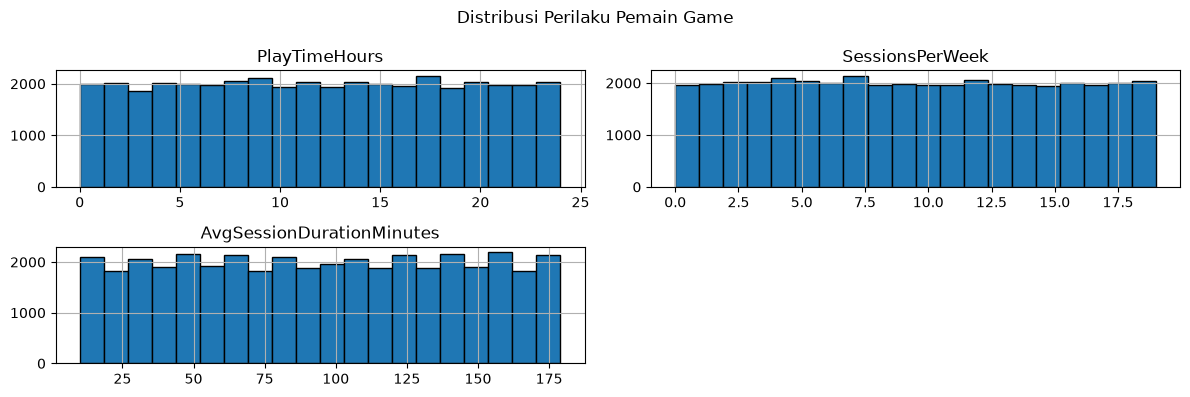

In [12]:
data[features].hist(
    figsize=(12, 4),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribusi Perilaku Pemain Game")
plt.tight_layout()
plt.show()

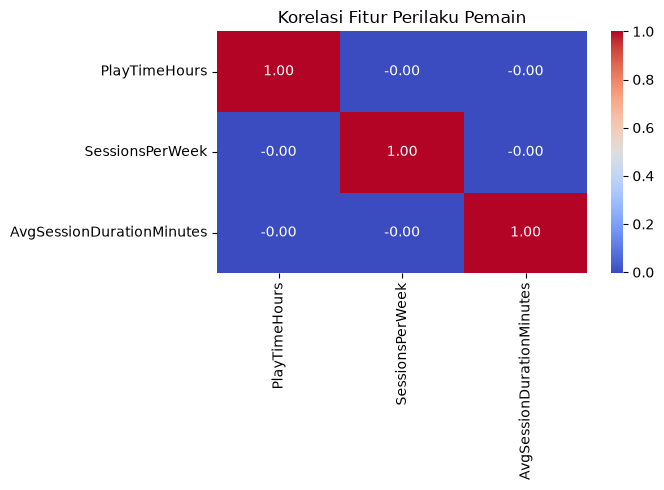

In [14]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    data[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Korelasi Fitur Perilaku Pemain")
plt.tight_layout()
plt.show()

In [15]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(data[features])

print("Standardisasi berhasil.")
print("Ukuran data hasil standardisasi:", X_scaled.shape)

Standardisasi berhasil.
Ukuran data hasil standardisasi: (40034, 3)


In [ ]:
inertias = []
silhouette_scores = []
k_values = range(2, 8)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

hasil_k = pd.DataFrame({
    "Jumlah Cluster (k)": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(hasil_k)

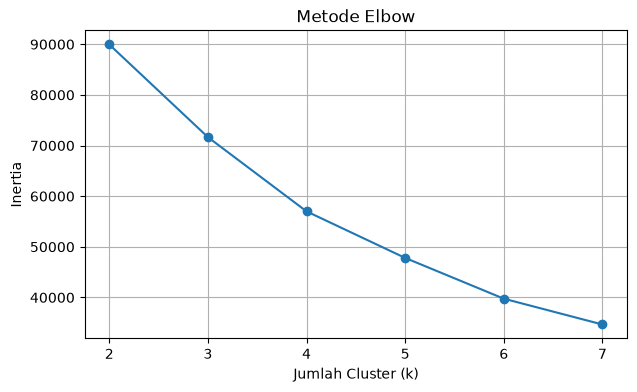

In [22]:
plt.figure(figsize=(7, 4))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.title("Metode Elbow")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [23]:
k_terpilih = 3

kmeans = KMeans(
    n_clusters=k_terpilih,
    random_state=42,
    n_init=10
)

data["Cluster"] = kmeans.fit_predict(X_scaled)

print("Clustering selesai.")
display(data.head())

Clustering selesai.


,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes,Cluster
0,16.271119,6,108,1
1,5.525961,5,144,2
2,8.223755,16,142,0
3,5.265351,9,85,2
4,15.531945,2,131,1


In [24]:
score = silhouette_score(
    X_scaled,
    data["Cluster"]
)

print("Jumlah cluster:", k_terpilih)
print("Silhouette Score:", round(score, 4))

Jumlah cluster: 3
Silhouette Score: 0.2399


In [25]:
jumlah_cluster = (
    data["Cluster"]
    .value_counts()
    .sort_index()
)

persentase_cluster = (
    data["Cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

ringkasan_cluster = pd.DataFrame({
    "Jumlah Pemain": jumlah_cluster,
    "Persentase (%)": persentase_cluster.round(2)
})

display(ringkasan_cluster)

,Jumlah Pemain,Persentase (%)
Cluster,,
0,12336,30.81
1,12736,31.81
2,14962,37.37


In [26]:
profil_cluster = data.groupby("Cluster")[features].mean().round(2)

print("Rata-rata fitur pada setiap cluster:")
display(profil_cluster)

Rata-rata fitur pada setiap cluster:


,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes
Cluster,,,
0,16.42,14.89,94.71
1,16.34,4.13,95.50
2,4.73,9.55,94.26


In [27]:
median_cluster = data.groupby("Cluster")[features].median().round(2)

print("Median fitur pada setiap cluster:")
display(median_cluster)

Median fitur pada setiap cluster:


,PlayTimeHours,SessionsPerWeek,AvgSessionDurationMinutes
Cluster,,,
0,16.51,15.0,95.0
1,16.56,4.0,96.0
2,4.55,10.0,94.0


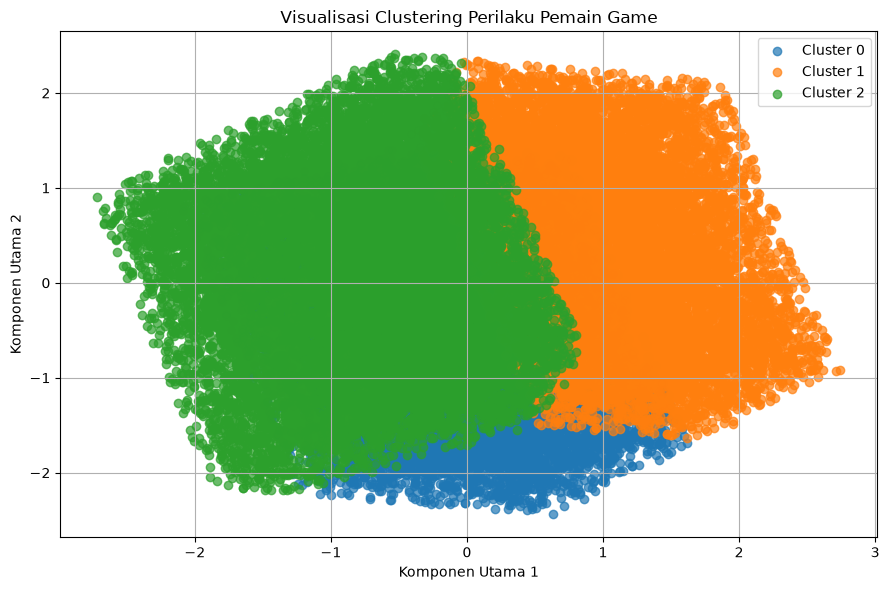

In [28]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

for cluster in sorted(data["Cluster"].unique()):
    mask = data["Cluster"] == cluster

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.xlabel("Komponen Utama 1")
plt.ylabel("Komponen Utama 2")
plt.title("Visualisasi Clustering Perilaku Pemain Game")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

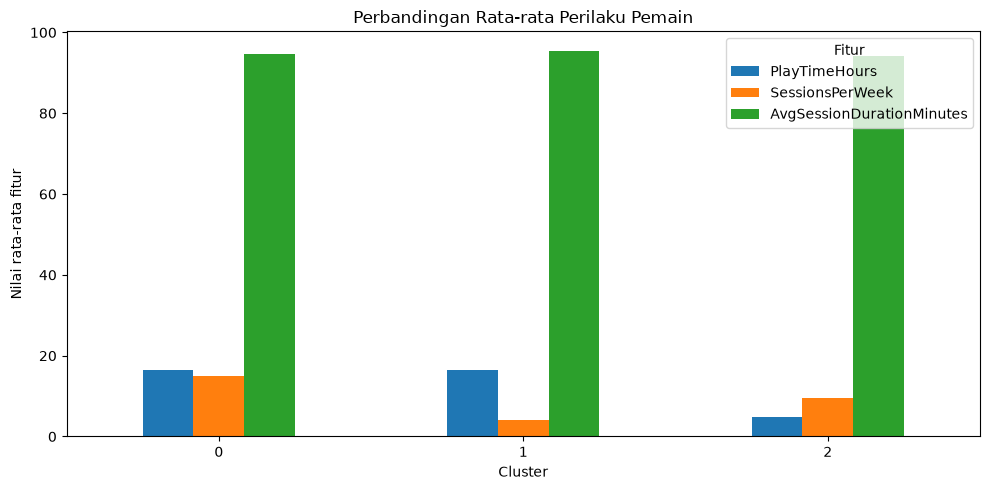

In [29]:
profil_cluster.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Perbandingan Rata-rata Perilaku Pemain")
plt.xlabel("Cluster")
plt.ylabel("Nilai rata-rata fitur")
plt.xticks(rotation=0)
plt.legend(title="Fitur")
plt.tight_layout()
plt.show()

In [30]:
data.to_csv(
    "hasil_clustering_perilaku_pemain.csv",
    index=False
)

profil_cluster.to_csv(
    "profil_cluster_pemain.csv"
)

ringkasan_cluster.to_csv(
    "jumlah_pemain_per_cluster.csv"
)

print("Semua hasil berhasil disimpan.")

Semua hasil berhasil disimpan.
